In [1]:
import torch
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.compose import ColumnTransformer

In [2]:
df = pd.read_csv("09-iris.csv")

In [3]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [5]:
df["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

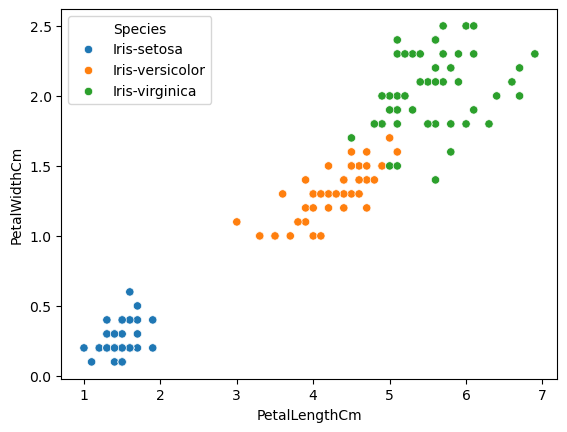

In [6]:
sns.scatterplot(data=df, x="PetalLengthCm", y="PetalWidthCm", hue="Species")
plt.show()

In [7]:
X = df.drop(["Id", "Species"], axis=1).values
y = df["Species"].values

encoder = LabelEncoder()
y = encoder.fit_transform(y)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

In [9]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train , dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

In [10]:
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

torch.Size([120, 4]) torch.Size([30, 4])
torch.Size([120]) torch.Size([30])


In [11]:
class IrisClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=4, out_features=16)
        self.layer_2 = nn.Linear(in_features=16, out_features=16)
        self.layer_3 = nn.Linear(in_features=16, out_features=3)
        
        self.relu = nn.ReLU()

    def forward(self, X: torch.tensor) -> torch.tensor:
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(X)))))      

In [12]:
class IrisClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear_layer_stack = nn.Sequential(  # sirasiyla calistir anlamaina gelir.
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16,16),
            nn.ReLU(),
            nn.Linear(16, 3)
        )

    def forward(self, X: torch.tensor) -> torch.tensor:
        return self.linear_layer_stack(X)

In [13]:
model = IrisClassifier()

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [14]:
def calculate_accuracy(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    accuracy = (correct / len(y_pred)) * 100
    return accuracy

In [15]:
y_logits = model(X_test)

In [16]:
y_pred_logits = torch.softmax(y_logits, dim = 1)

In [17]:
y_logits[:5]

tensor([[ 0.5061, -0.2374, -0.2501],
        [ 0.6482, -0.2887, -0.3839],
        [ 0.5031, -0.2816, -0.3005],
        [ 0.5058, -0.2888, -0.3097],
        [ 0.5085, -0.2291, -0.2489]], grad_fn=<SliceBackward0>)

In [18]:
y_pred_logits[:5]

tensor([[0.5142, 0.2445, 0.2414],
        [0.5721, 0.2241, 0.2038],
        [0.5252, 0.2396, 0.2352],
        [0.5279, 0.2385, 0.2336],
        [0.5136, 0.2456, 0.2408]], grad_fn=<SliceBackward0>)

In [19]:
torch.manual_seed(42)
epochs = 200

train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

for epoch in range(epochs):
    model.train()

    logits = model(X_train)
    loss = loss_fn(logits, y_train)
    
    pred = torch.softmax(logits, dim=1).argmax(dim=1)
    acc = calculate_accuracy(y_train, pred)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())
    train_accuracies.append(acc)

    model.eval()
    with torch.inference_mode():
        test_logits = model(X_test)
        test_loss = loss_fn(test_logits, y_test)
        
        test_pred = torch.softmax(test_logits, dim = 1).argmax(dim=1)
        test_acc = calculate_accuracy(y_test, test_pred)
    test_losses.append(test_loss.item())
    test_accuracies.append(test_acc)

    if epoch % 20 == 0:
        print(f"Epocs:{epoch}, Train Loss:{loss:.4f}, Train Accuracy:{acc:.4f}, Test Loss:{test_loss:.4f}, Test Accuracy:{test_acc:.4f}")

Epocs:0, Train Loss:1.2585, Train Accuracy:33.3333, Test Loss:1.1763, Test Accuracy:33.3333
Epocs:20, Train Loss:0.6833, Train Accuracy:66.6667, Test Loss:0.6467, Test Accuracy:66.6667
Epocs:40, Train Loss:0.2338, Train Accuracy:96.6667, Test Loss:0.2247, Test Accuracy:100.0000
Epocs:60, Train Loss:0.0836, Train Accuracy:98.3333, Test Loss:0.0803, Test Accuracy:100.0000
Epocs:80, Train Loss:0.0638, Train Accuracy:97.5000, Test Loss:0.0549, Test Accuracy:100.0000
Epocs:100, Train Loss:0.0583, Train Accuracy:98.3333, Test Loss:0.0480, Test Accuracy:100.0000
Epocs:120, Train Loss:0.0553, Train Accuracy:98.3333, Test Loss:0.0451, Test Accuracy:100.0000
Epocs:140, Train Loss:0.0531, Train Accuracy:98.3333, Test Loss:0.0442, Test Accuracy:100.0000
Epocs:160, Train Loss:0.0512, Train Accuracy:98.3333, Test Loss:0.0440, Test Accuracy:100.0000
Epocs:180, Train Loss:0.0500, Train Accuracy:98.3333, Test Loss:0.0432, Test Accuracy:100.0000


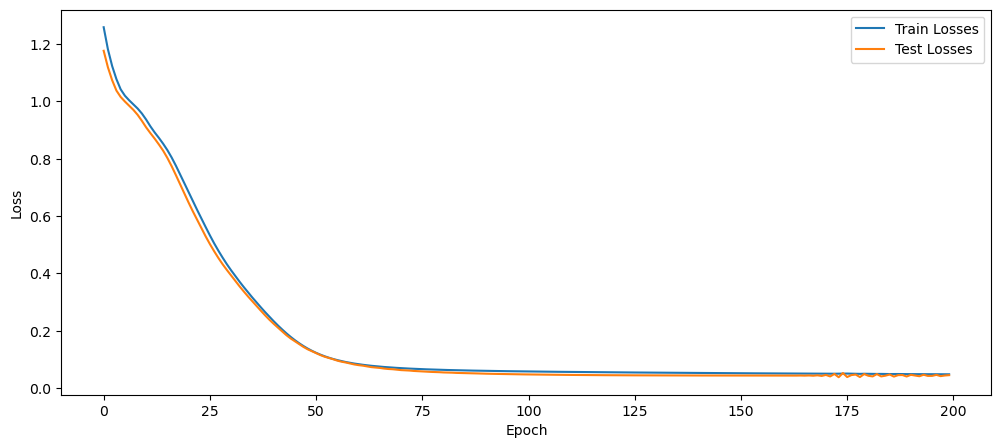

In [20]:
plt.figure(figsize=(12,5))
plt.plot(train_losses, label="Train Losses")
plt.plot(test_losses, label="Test Losses")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

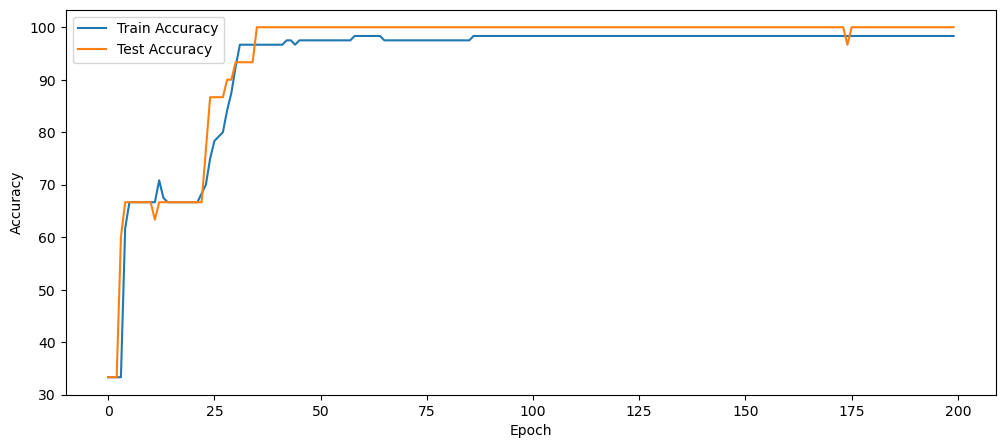

In [21]:
plt.figure(figsize=(12,5))
plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(test_accuracies, label="Test Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [22]:
new_sample = np.array([[5.1, 3.5, 1.4, 0.2]])

In [23]:
new_sample_tensor = torch.tensor(new_sample, dtype=torch.float32)

In [24]:
new_sample_tensor.shape

torch.Size([1, 4])

In [25]:
model.eval()
with torch.inference_mode():
    logits = model(new_sample_tensor)
    probs = torch.softmax(logits, dim=1)
    predicted_class = torch.argmax(probs, dim=1).item()

In [26]:
print(predicted_class)

0


In [27]:
encoder.inverse_transform([predicted_class])[0]

'Iris-setosa'

In [28]:
# torchmetrics

In [29]:
!pip install torchmetrics

In [30]:
from torchmetrics.classification import MulticlassAccuracy

In [31]:
accuracy = MulticlassAccuracy(num_classes=3)

In [32]:
epochs = 200
model_2 = IrisClassifier()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_2.parameters(), lr=0.01)

for epoch in range(epochs):
    
    model_2.train()
    logits = model_2(X_train)
    loss = loss_fn(logits, y_train)
                                                     # .softmax -> metodu icindeki dim=1 .softmax methodunu her satira uygulanmasi icin.
    pred = torch.softmax(logits, dim=1).argmax(dim=1) # .argmax -> metodu ise en yuksek olasiliga sahip sinifin indexini alir.
    acc = accuracy(pred, y_train).item() * 100 #torchmetric'in accuracy -> metodu tensor dondurur tensorden cikarmak icin .item() kullanabiliriz.   

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model_2.eval()
    with torch.inference_mode():
        test_logits = model_2(X_test)
        test_loss = loss_fn(test_logits, y_test)
        
        test_pred = torch.softmax(test_logits, dim=1).argmax(dim=1)
        test_acc = accuracy(test_pred, y_test).item() * 100

    if epoch % 20 == 0:
        print(f"Epoch:{epoch}, Train Loss:{loss:.4f}, Train Accuracy:{acc:.4f}, Test Loss:{test_loss:.4f}, Test Accuracy:{test_acc:.4f}")

Epoch:0, Train Loss:1.1047, Train Accuracy:33.3333, Test Loss:1.0137, Test Accuracy:66.6667
Epoch:20, Train Loss:0.4823, Train Accuracy:66.6667, Test Loss:0.4638, Test Accuracy:70.0000
Epoch:40, Train Loss:0.1671, Train Accuracy:97.5000, Test Loss:0.1665, Test Accuracy:100.0000
Epoch:60, Train Loss:0.0663, Train Accuracy:97.5000, Test Loss:0.0614, Test Accuracy:100.0000
Epoch:80, Train Loss:0.0570, Train Accuracy:98.3333, Test Loss:0.0456, Test Accuracy:100.0000
Epoch:100, Train Loss:0.0537, Train Accuracy:98.3333, Test Loss:0.0437, Test Accuracy:100.0000
Epoch:120, Train Loss:0.0516, Train Accuracy:98.3333, Test Loss:0.0434, Test Accuracy:100.0000
Epoch:140, Train Loss:0.0497, Train Accuracy:98.3333, Test Loss:0.0434, Test Accuracy:100.0000
Epoch:160, Train Loss:0.0481, Train Accuracy:98.3333, Test Loss:0.0441, Test Accuracy:100.0000
Epoch:180, Train Loss:0.0468, Train Accuracy:98.3333, Test Loss:0.0407, Test Accuracy:100.0000


In [33]:
from torchmetrics.classification import MulticlassConfusionMatrix

In [34]:
confusion_matrix = MulticlassConfusionMatrix(num_classes=3)

In [35]:
matrix = confusion_matrix(test_pred, y_test)
matrix

tensor([[10,  0,  0],
        [ 0, 10,  0],
        [ 0,  0, 10]])

In [36]:
from torchmetrics.utilities.plot import plot_confusion_matrix

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Predicted class', ylabel='True class'>)

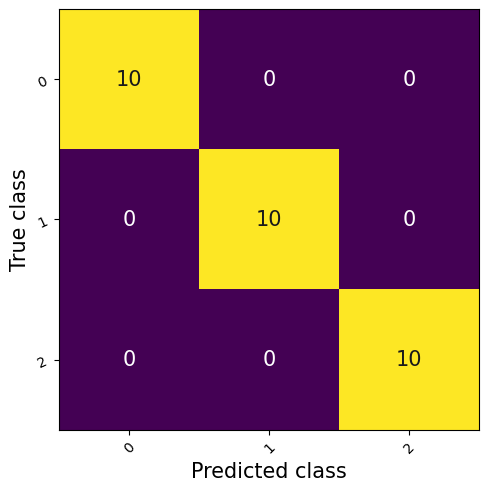

In [37]:
plot_confusion_matrix(matrix)

In [38]:
from pathlib import Path

In [44]:
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)# models klasoru yoksa olusturma eger yoksa bu klasoru olustur.

MODEL_NAME = "iris_classification_model.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

torch.save(obj=model_2.state_dict(), f=MODEL_SAVE_PATH)

In [46]:
model_2.state_dict()

OrderedDict([('linear_layer_stack.0.weight',
              tensor([[ 0.5119,  0.6784, -0.3962, -0.0420],
                      [-0.1096,  0.1009, -0.2434,  0.2936],
                      [ 0.4769, -0.4442,  0.7564,  0.5707],
                      [ 0.3387, -0.0715,  0.5747,  0.3651],
                      [ 0.4690,  0.2974, -0.4619, -0.3396],
                      [-0.2304, -0.0586, -0.2031,  0.3317],
                      [-0.3947, -0.2305, -0.1412, -0.3006],
                      [ 0.1709, -0.5428,  0.7875,  0.0657],
                      [ 0.5914,  0.4313, -0.2294,  0.0036],
                      [ 0.2826,  0.5954,  0.1721, -0.3705],
                      [ 0.1657, -0.2685,  0.6000,  1.0520],
                      [ 0.3489, -0.4508,  0.6718,  0.7337],
                      [ 0.2539, -0.3048, -0.4950, -0.1932],
                      [-0.4486,  0.1517,  0.5017,  0.8711],
                      [ 0.3057,  0.2871,  0.2090, -0.8413],
                      [-0.0435, -0.4149,  0.0797, -0.24

In [47]:
loaded_model = IrisClassifier()

In [49]:
type(torch.load(MODEL_SAVE_PATH))

collections.OrderedDict

In [50]:
loaded_model.load_state_dict(torch.load(MODEL_SAVE_PATH))

<All keys matched successfully>

In [55]:
new_sample = np.array([[5.1, 3.5, 1.4, 0.2]])
new_sample_tensor = torch.tensor(new_sample, dtype=torch.float32)
loaded_model.eval()
with torch.inference_mode():
    logits = loaded_model(new_sample_tensor)
    probs = torch.softmax(logits, dim=1)
    predicted_class = torch.argmax(probs, dim=1).item()

encoder.inverse_transform([predicted_class])[0]

'Iris-setosa'